# Parte A: datos, preprocesamiento y evaluación
**Proyecto Final IA 2026 - Predicción de deserción estudiantil con PyTorch (Persona A)**

El preprocesamiento sigue el mismo orden del notebook del profesor (`TAller_kmeans`):
`head / info` → seleccionar columnas → `describe` → nulos → histogramas → boxplots → imputar → outliers → correlación y variables redundantes → escalar.
La diferencia está en lo que cambia por ser una red neuronal con train / validación / test (se explica en cada celda).

**Entrega a la Persona B:** `train_loader`, `val_loader`, `test_loader`, `input_dim`, `scaler.pkl`, `feature_info.pkl` y la función `preparar_entrada`.
**Recibe de la Persona B:** `best_model` (entrenado) para evaluarlo en A13.

# Proyecto Final IA 2026: Sistema inteligente para predecir la deserción estudiantil

## 0. Definición del problema
**Problema:** muchas instituciones pierden estudiantes que abandonan sus estudios y se enteran cuando ya es tarde. Se quiere un sistema que, con los datos **académicos** (notas y unidades curriculares de los dos primeros semestres) y **socioeconómicos** (estudios y ocupación de los padres, deuda, matrícula al día, beca), estime la **probabilidad de que un estudiante abandone**, para que la institución pueda ofrecerle apoyo a tiempo.

| Elemento | Definición |
|---|---|
| Tipo de problema | Clasificación **binaria** supervisada |
| Variable a predecir | `1` = abandona (Dropout), `0` = no abandona (Graduate o Enrolled) |
| Método | Red neuronal feed-forward (perceptrón multicapa) en **PyTorch** |
| Medidas de evaluación | **Accuracy** y **F1-score** (el F1 importa porque las clases están desbalanceadas, ~32 % abandona) |
| Despliegue | Aplicación web con **Streamlit** que recibe los datos de un estudiante y devuelve la probabilidad de abandono |

**Estructura del notebook:** Parte A (datos y preprocesamiento) → **Parte B (modelo)** → Evaluación final → **Parte C (despliegue)**.


In [1]:
# ============================================================
# CONFIGURACIÓN INICIAL
# ============================================================
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import torch
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# Semilla: para que los resultados se puedan repetir al volver a correr el notebook.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cpu


## A1. Cargar el dataset (igual que el profe: head e info)

In [2]:
# encoding="utf-8-sig": el archivo trae un carácter invisible al inicio (BOM) que dañaría el nombre de la primera columna.
df = pd.read_csv("dataset.csv", encoding="utf-8-sig")
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                             4424

## A2. Seleccionar las columnas (como el profe: `df = df[[...]]`)
Solo entrenamos con variables **académicas** y **socioeconómicas**. Las demográficas (edad, género, estado civil, nacionalidad)
y los indicadores económicos del país (desempleo, inflación, PIB) quedan fuera: no describen lo que la institución puede observar
del rendimiento del estudiante y algunas pueden generar discriminación.

In [4]:
columnas_modelo = [
    # Socioeconómicas
    "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
    "Debtor", "Tuition fees up to date", "Scholarship holder",
    # Académicas (primer semestre)
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
    # Académicas (segundo semestre)
    "Curricular units 2nd sem (credited)", "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)", "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)", "Curricular units 2nd sem (without evaluations)",
]

# Mantenemos Target (lo que queremos predecir) junto con las columnas elegidas
df = df[columnas_modelo + ["Target"]]
print("Filas y columnas:", df.shape)

Filas y columnas: (4424, 20)


## A3. Explorar: describe, nulos, histogramas y boxplots (igual que el profe)

In [5]:
# Las únicas variables numéricas de verdad son las unidades curriculares.
# El resto son categóricas (códigos) o sí/no, aunque pandas las muestre como int64.
columnas_numericas = [c for c in columnas_modelo if c.startswith("Curricular")]
df[columnas_numericas].describe()

,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations)
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316
std,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000
50%,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000
75%,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000
max,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000


In [6]:
# Nulos: cantidad y porcentaje (igual que el profe)
print(df.isnull().sum())
print()
print(df.isnull().sum() / len(df) * 100)

Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Debtor                                            0
Tuition fees up to date                           0
Scholarship holder                                0
Curricular units 1st sem (credited)               0
Curricular units 1st sem (enrolled)               0
Curricular units 1st sem (evaluations)            0
Curricular units 1st sem (approved)               0
Curricular units 1st sem (grade)                  0
Curricular units 1st sem (without evaluations)    0
Curricular units 2nd sem (credited)               0
Curricular units 2nd sem (enrolled)               0
Curricular units 2nd sem (evaluations)            0
Curricular units 2nd sem (approved)               0
Curricular units 2nd sem (grade)                  0
Curricular units 2nd sem (without evaluations)    0
Target      

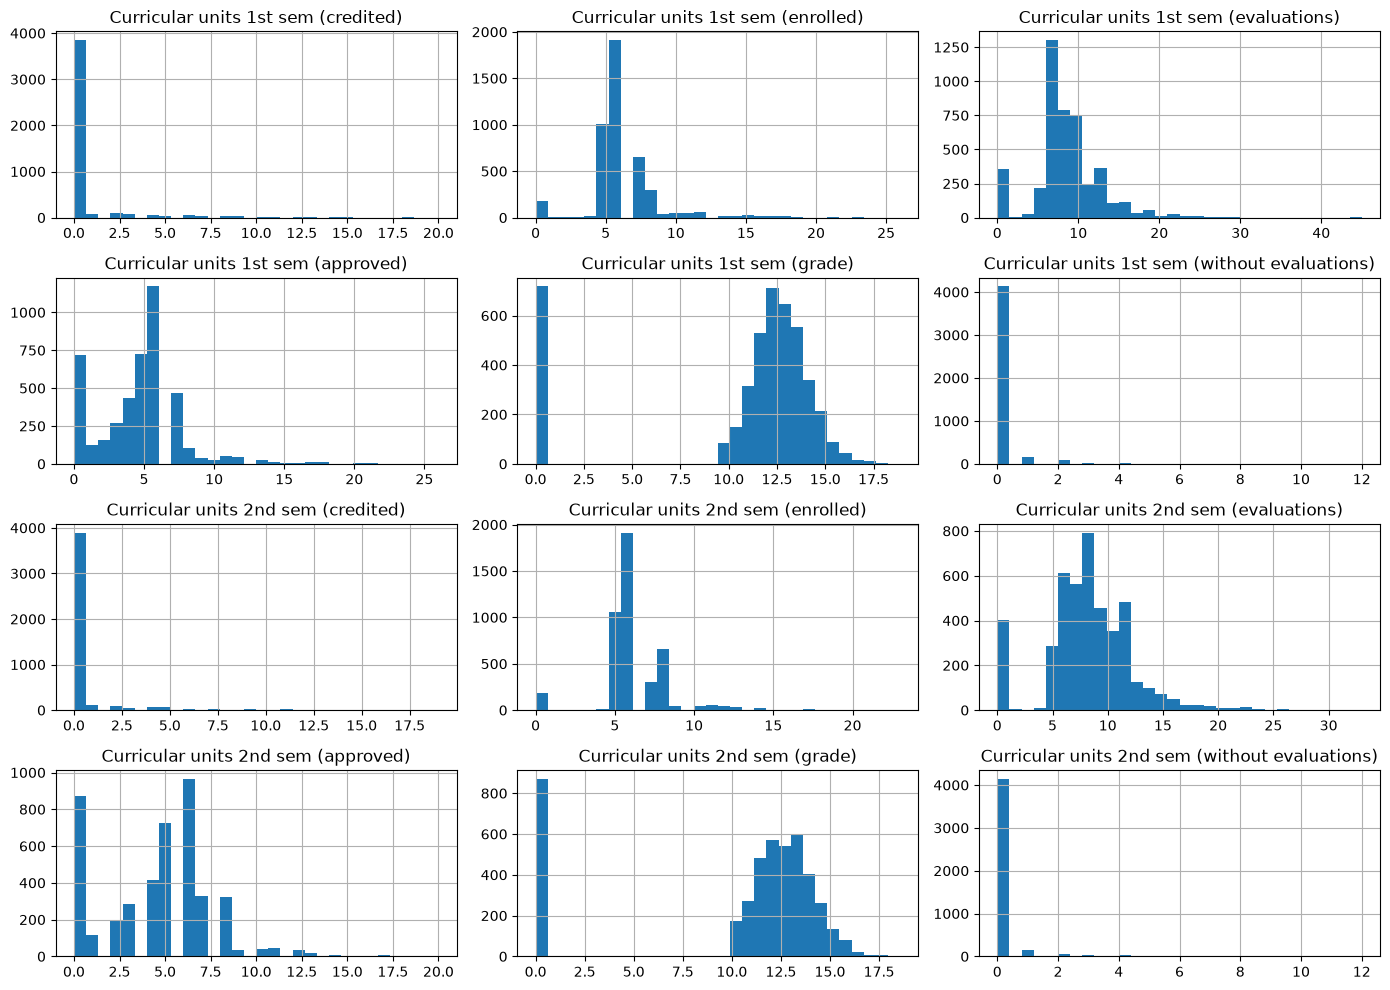

In [7]:
# Histogramas de las variables numéricas
df[columnas_numericas].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

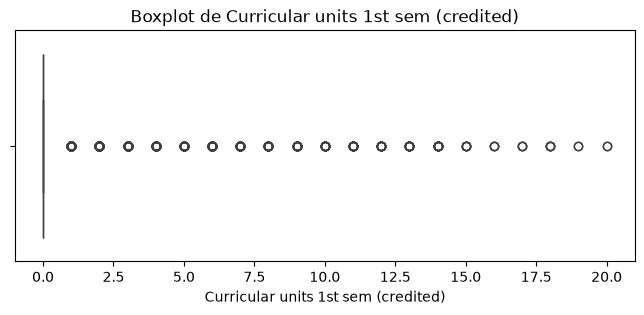

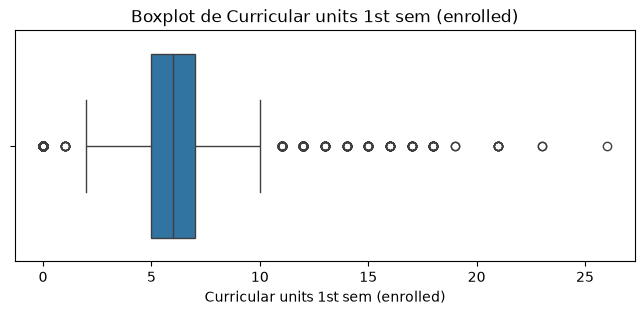

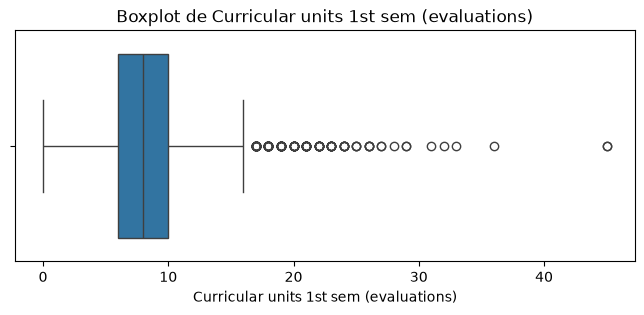

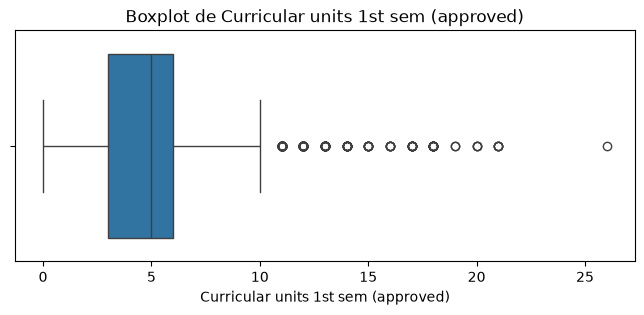

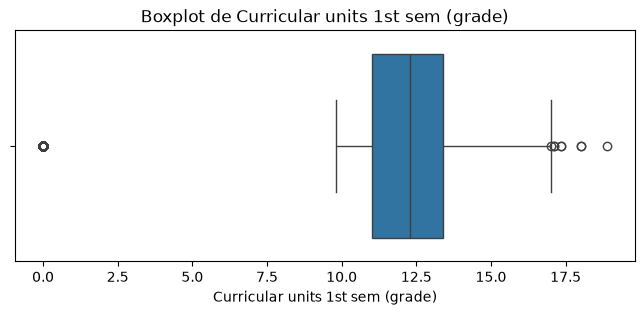

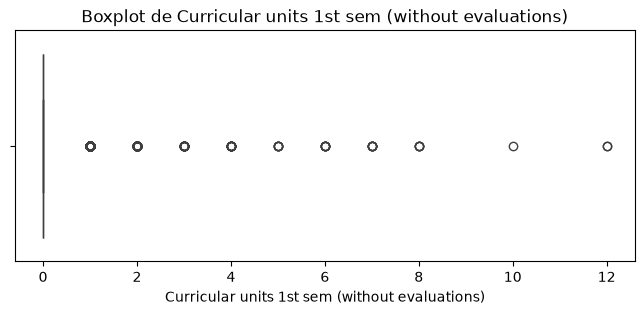

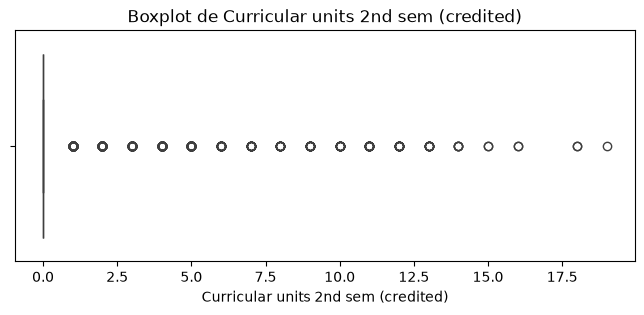

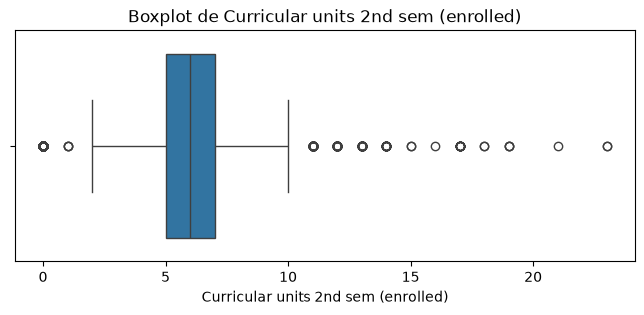

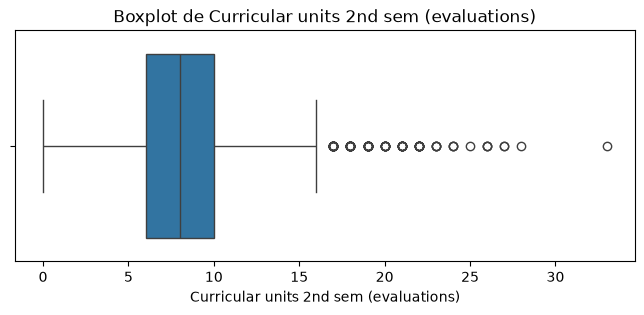

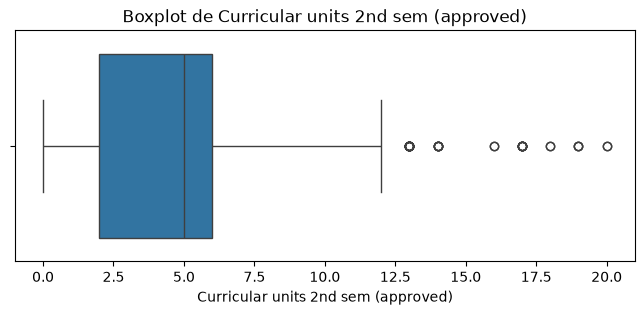

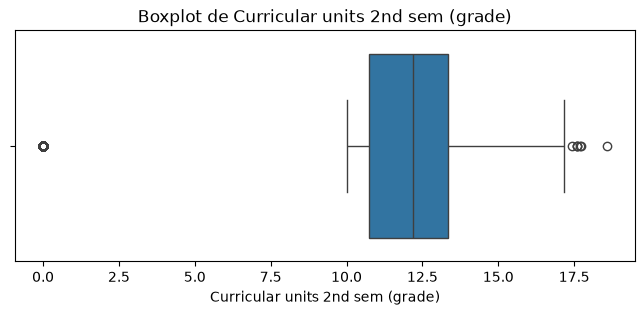

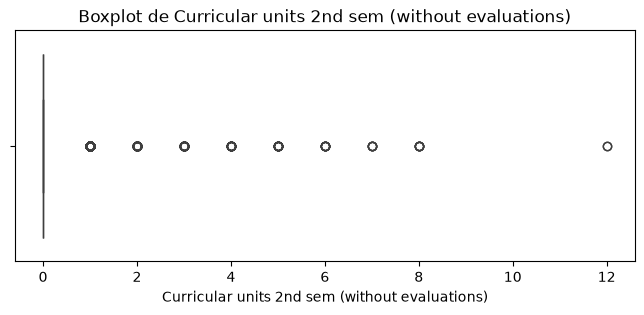

In [8]:
# Boxplot de cada variable por separado (igual que el profe)
for columna in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[columna])
    plt.title(f"Boxplot de {columna}")
    plt.show()

## A4. Imputar nulos y tratar outliers
**Nulos:** el profe imputa la mediana donde hay nulos. Aquí no hay ninguno, así que esta línea no cambia nada,
pero deja el paso hecho igual que en el notebook del profe.

**Outliers:** el profe elimina filas extremas (`tempo >= 1000`). Aquí **no se eliminan**. Los valores extremos de las notas son estudiantes con nota 0,
y no son errores de datos: son estudiantes que no presentaron evaluaciones y abandonan casi siempre. Borrarlos eliminaría a quienes queremos detectar.

In [9]:
# Imputar la mediana en las numéricas (como el profe). Sin nulos, no cambia nada.
df[columnas_numericas] = df[columnas_numericas].fillna(df[columnas_numericas].median())
print("Nulos después de imputar:", df.isnull().sum().sum())

Nulos después de imputar: 0


In [10]:
# Evidencia de por qué NO borramos outliers (útil para la sustentación)
abandona = (df["Target"] == "Dropout")
for sem in ["1st", "2nd"]:
    nota0 = df[f"Curricular units {sem} sem (grade)"] == 0
    print(f"{sem} semestre: {nota0.sum()} estudiantes con nota 0 ({nota0.mean()*100:.1f}%) "
          f"-> abandona el {abandona[nota0].mean()*100:.1f}% (en todo el dataset abandona el {abandona.mean()*100:.1f}%)")

1st semestre: 718 estudiantes con nota 0 (16.2%) -> abandona el 79.4% (en todo el dataset abandona el 32.1%)
2nd semestre: 870 estudiantes con nota 0 (19.7%) -> abandona el 83.6% (en todo el dataset abandona el 32.1%)


## A5. Matriz de correlación y eliminación de variables redundantes
Antes de armar `X`, dividir y escalar, se revisa la correlación de Pearson entre las variables numéricas.
Si dos variables tienen correlación **mayor a 0.90**, dicen casi lo mismo: dejar las dos no aporta información nueva, pero sí agrega
peso a la red. Entre cada par se conserva la del **1.er semestre** (se conoce antes, así que permite detectar el riesgo más temprano) y se elimina la del **2.º semestre**.

**¿Por qué antes del MinMaxScaler?** La correlación no cambia al escalar, así que se puede calcular antes. Y borrar las columnas **antes** de armar `X`
hace que `X`, el scaler, el modelo, `preparar_entrada` y la app trabajen todos con las mismas columnas (si se borraran después, el modelo las seguiría usando).


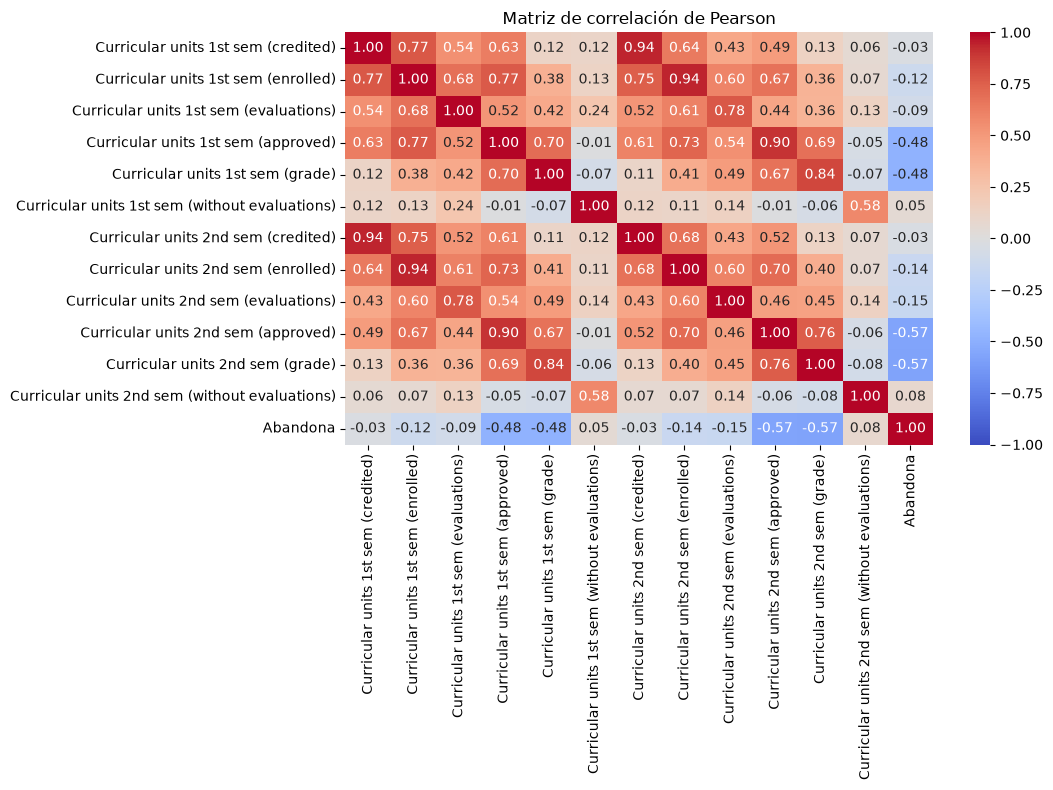

Pares con correlación > 0.9:
  Curricular units 1st sem (credited)  <->  Curricular units 2nd sem (credited): 0.945
  Curricular units 1st sem (enrolled)  <->  Curricular units 2nd sem (enrolled): 0.943
  Curricular units 1st sem (approved)  <->  Curricular units 2nd sem (approved): 0.904


In [11]:
# Correlación de Pearson entre las variables numéricas y el abandono
df_corr = df[columnas_numericas].copy()
df_corr["Abandona"] = (df["Target"] == "Dropout").astype(int)
correlacion = df_corr.corr(method="pearson")

plt.figure(figsize=(11, 8))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()
# Se ve que las notas y las unidades aprobadas tienen correlación negativa con el abandono:
# a mejores notas y más aprobadas, menos abandono. Las de 1.er y 2.º semestre se parecen entre sí.

# Pares de variables con correlación mayor a 0.90 (redundantes)
UMBRAL = 0.90
print(f"Pares con correlación > {UMBRAL}:")
for i, a in enumerate(columnas_numericas):
    for b in columnas_numericas[i + 1:]:
        if abs(correlacion.loc[a, b]) > UMBRAL:
            print(f"  {a}  <->  {b}: {correlacion.loc[a, b]:.3f}")


In [12]:
# Se elimina la variable del 2.º semestre de cada par con correlación > 0.90
columnas_redundantes = [
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)",
]
df = df.drop(columns=columnas_redundantes)

# Actualizamos las listas para que TODO lo que sigue (X, scaler, modelo, app) use solo las columnas que quedan
columnas_modelo    = [c for c in columnas_modelo    if c not in columnas_redundantes]
columnas_numericas = [c for c in columnas_numericas if c not in columnas_redundantes]
print("Columnas eliminadas:", len(columnas_redundantes), "| Columnas que quedan para el modelo:", len(columnas_modelo))


Columnas eliminadas: 3 | Columnas que quedan para el modelo: 16


## A6. Variable objetivo binaria y distribución de clases

Proporción de estudiantes que abandonan: 0.321


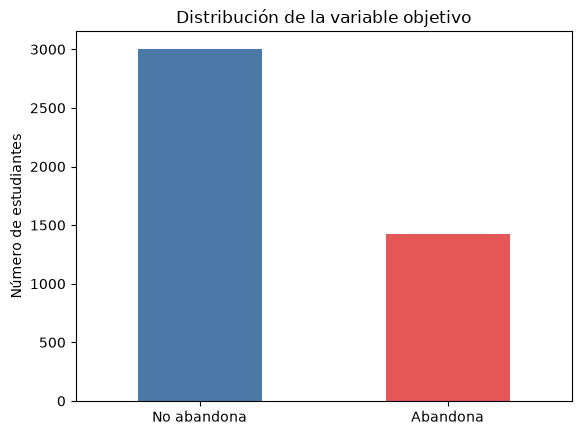

In [13]:
# El dataset original tiene 3 clases: Graduate, Dropout y Enrolled.
# Lo convertimos en BINARIO: 1 = Dropout (abandona), 0 = no abandona (Graduate o Enrolled).
# PREGUNTA DEL PROFE: "¿Por qué binario?" -> la pregunta del problema es detectar a quien abandona;
# Enrolled aún no termina, así que se interpreta como "no ha abandonado hasta ahora".
y = (df["Target"] == "Dropout").astype(int).values
X = df.drop(columns=["Target"])

print("Proporción de estudiantes que abandonan:", round(y.mean(), 3))
pd.Series(y).map({0: "No abandona", 1: "Abandona"}).value_counts().plot(kind="bar", color=["#4C78A8", "#E45756"])
plt.title("Distribución de la variable objetivo")
plt.ylabel("Número de estudiantes")
plt.xticks(rotation=0)
plt.show()
# Las clases están desbalanceadas (~32% / 68%): por eso usamos F1-score además de Accuracy.

## A7. Variables categóricas → one-hot
Mother's / Father's qualification y occupation son **códigos de categorías** (nivel educativo y ocupación), no cantidades,
aunque pandas las lea como `int64`. Se convierten a tipo `category` y luego a columnas de 0 y 1 (one-hot).

`Debtor`, `Tuition fees up to date` y `Scholarship holder` ya son 0/1, así que se dejan como están.

> `USAR_ONEHOT = False` deja los códigos como números (más simple pero menos correcto). Pueden probar ambos y comparar el F1 en validación.

In [14]:
USAR_ONEHOT = True

columnas_categoricas = ["Mother's qualification", "Father's qualification",
                        "Mother's occupation", "Father's occupation"]

# Valores por defecto para el formulario del despliegue (mediana en numéricas, moda en el resto)
valores_defecto = {c: float(X[c].median()) if c in columnas_numericas else float(X[c].mode()[0])
                   for c in columnas_modelo}
# Categorías posibles de cada variable categórica (para codificar igual en el despliegue)
niveles = {c: sorted(int(v) for v in X[c].unique()) for c in columnas_categoricas}

if USAR_ONEHOT:
    # PREGUNTA DEL PROFE: "¿Por qué one-hot?" -> si dejamos el código 46 como número, la red cree que
    # "vale más" que el 5. One-hot le dice que son categorías distintas, sin orden entre ellas.
    for col in columnas_categoricas:
        X[col] = X[col].astype("category")
    X = pd.get_dummies(X, columns=columnas_categoricas, dtype=int)   # dtype=int: sin esto salen True/False

columnas_finales = list(X.columns)
input_dim = X.shape[1]            # número de neuronas de entrada de la red
print("Variables de entrada (input_dim):", input_dim)

Variables de entrada (input_dim): 153


## A8. División en train / validación / test

In [15]:
# train (64%) para aprender, validación (16%) para comparar configuraciones, test (20%) solo para la evaluación final.
# stratify mantiene la misma proporción de abandono (~32%) en las tres partes.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X.values, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.20, stratify=y_trainval, random_state=SEED)

print("Train:", X_train.shape, "| Validación:", X_val.shape, "| Test:", X_test.shape)
print("Abandono -> train:", round(y_train.mean(), 3), "| val:", round(y_val.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (2831, 153) | Validación: (708, 153) | Test: (885, 153)
Abandono -> train: 0.321 | val: 0.321 | test: 0.321


## A9. Escalar con MinMaxScaler (el mismo del profe)
`MinMaxScaler` lleva cada variable al rango [0, 1]. A diferencia del notebook del profe, aquí se ajusta **solo con train**
y luego se aplica a validación y test.

**PREGUNTA DEL PROFE:** "¿Por qué el scaler se ajusta solo con train?"
**RESPUESTA:** para evitar fuga de datos. En K-means no hay train y test, pero en una red, si el escalador viera test,
la red "conocería" información que no debería y la evaluación saldría demasiado optimista.

In [16]:
scaler = MinMaxScaler().fit(X_train)      # aprende mínimo y máximo SOLO de train
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print("Train -> mínimo:", X_train_s.min(), "| máximo:", X_train_s.max())
# En val y test pueden salir valores un poco fuera de [0, 1] si hay datos más extremos que los de train. Es normal.

joblib.dump(scaler, "scaler.pkl")

Train -> mínimo: 0.0 | máximo: 1.0


['scaler.pkl']

## A10. Función para el despliegue y archivos para la Persona B
Con one-hot, el formulario de la app no puede pasar los datos directo al scaler: primero hay que codificarlos igual que en el entrenamiento.
`preparar_entrada` recibe los datos originales de un estudiante (las 16 columnas) y devuelve el vector listo para la red.

In [17]:
def preparar_entrada(df_raw):
    # Convierte datos crudos de estudiantes (DataFrame con columnas_modelo) en la matriz escalada que espera la red.
    d = df_raw[columnas_modelo].copy()
    if USAR_ONEHOT:
        for col in columnas_categoricas:
            d[col] = pd.Categorical(d[col], categories=niveles[col])   # mismas categorías del entrenamiento
        d = pd.get_dummies(d, columns=columnas_categoricas, dtype=int)
    d = d.reindex(columns=columnas_finales, fill_value=0)              # mismo orden de columnas
    return scaler.transform(d.values)

# Prueba: preparar los primeros 5 estudiantes originales debe dar la misma matriz que el entrenamiento
prueba = preparar_entrada(pd.read_csv("dataset.csv", encoding="utf-8-sig").head(5))
print("Forma:", prueba.shape, "| coincide con input_dim:", prueba.shape[1] == input_dim)

joblib.dump({"columnas_modelo": columnas_modelo,
             "columnas_categoricas": columnas_categoricas,
             "columnas_finales": columnas_finales,
             "niveles": niveles,
             "valores_defecto": valores_defecto,
             "usar_onehot": USAR_ONEHOT}, "feature_info.pkl")
print("Guardados: scaler.pkl y feature_info.pkl")

Forma: (5, 153) | coincide con input_dim: True
Guardados: scaler.pkl y feature_info.pkl


## A11. Tensores y DataLoaders

In [18]:
# PyTorch trabaja con tensores. float32 es el tipo que esperan las capas de la red.
# En y usamos unsqueeze(1) para que tenga forma (n, 1), igual que la salida de la red.
def a_dataset(X_, y_):
    return TensorDataset(torch.tensor(X_, dtype=torch.float32),
                         torch.tensor(y_, dtype=torch.float32).unsqueeze(1))

# DataLoader: entrega los datos en lotes de 64. shuffle=True solo en train (mezcla el orden en cada época).
train_loader = DataLoader(a_dataset(X_train_s, y_train), batch_size=64, shuffle=True)
val_loader   = DataLoader(a_dataset(X_val_s,   y_val),   batch_size=256, shuffle=False)
test_loader  = DataLoader(a_dataset(X_test_s,  y_test),  batch_size=256, shuffle=False)

print("Listo. input_dim =", input_dim, "| lotes en train:", len(train_loader))
# >>> A le pasa a B: train_loader, val_loader, test_loader, input_dim, scaler.pkl, feature_info.pkl y preparar_entrada

Listo. input_dim = 153 | lotes en train: 45


In [19]:
# (Opcional) Guardar el dataset ya preprocesado, por si hay que compartirlo o revisarlo
df_procesado = pd.DataFrame(X.values, columns=columnas_finales)
df_procesado["Abandona"] = y
df_procesado.to_csv("dataset_procesado.csv", index=False)
print("Guardado dataset_procesado.csv:", df_procesado.shape)

Guardado dataset_procesado.csv: (4424, 154)


# Parte B: Modelo (red neuronal en PyTorch)
Aquí se define la red, se entrena con `train_loader`, se compara varias configuraciones con **validación** y se elige la mejor (`best_model`).
El conjunto de **test no se toca** hasta la evaluación final: si lo usáramos para elegir el modelo, el resultado saldría demasiado optimista.


## B1. Arquitectura de la red
Se usa un perceptrón multicapa: `entrada → capa oculta 1 → capa oculta 2 → 1 salida`.

- **ReLU** entre capas: introduce no linealidad, sin ella la red sería solo una regresión lineal.
- **Dropout**: apaga neuronas al azar durante el entrenamiento para reducir el sobreajuste (el notebook ya menciona que `model.eval()` lo apaga en la evaluación).
- **Una sola salida sin sigmoide**: devuelve un *logit*. La sigmoide se aplica después (en `probabilidades`, A13), y la función de pérdida `BCEWithLogitsLoss` ya la incluye por dentro, lo que es numéricamente más estable.


In [20]:
import torch.nn as nn
import torch.optim as optim
import copy

class RedDesercion(nn.Module):
    def __init__(self, input_dim, h1=64, h2=32, dropout=0.3):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(input_dim, h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2),        nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h2, 1),                       # salida: logit de "abandona"
        )

    def forward(self, x):
        return self.red(x)

print(RedDesercion(input_dim))


RedDesercion(
  (red): Sequential(
    (0): Linear(in_features=153, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


## B2. Funciones de entrenamiento y validación
- **Pérdida:** `BCEWithLogitsLoss`, la estándar para clasificación binaria.
- **Optimizador:** `Adam` (ajusta solo la tasa de aprendizaje de cada peso, funciona bien sin mucho ajuste) con `weight_decay` pequeño como regularización.
- **Early stopping:** si el F1 de validación no mejora en `paciencia` épocas seguidas, se detiene y se recupera el mejor estado. Evita entrenar de más y memorizar el train.
- Cada época: `model.train()` (Dropout activo) para aprender, `model.eval()` (Dropout apagado) para medir en validación.


In [21]:
def evaluar_loader(model, loader, criterio):
    # Devuelve (pérdida, F1, accuracy) de un DataLoader, sin actualizar pesos
    model.eval()
    perdida, probs, reales = 0.0, [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            perdida += criterio(logits, yb).item() * len(xb)
            probs.append(torch.sigmoid(logits).cpu())
            reales.append(yb.cpu())
    probs = torch.cat(probs).numpy().ravel()
    reales = torch.cat(reales).numpy().ravel()
    pred = (probs >= 0.5).astype(int)
    return perdida / len(loader.dataset), f1_score(reales, pred), accuracy_score(reales, pred)


def entrenar(h1, h2, dropout, lr, weight_decay=1e-4, epocas=100, paciencia=10):
    torch.manual_seed(SEED)                       # misma inicialización -> comparación justa entre configuraciones
    model = RedDesercion(input_dim, h1, h2, dropout).to(device)
    criterio = nn.BCEWithLogitsLoss()
    optimizador = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    hist = {"loss_train": [], "loss_val": [], "f1_val": []}
    mejor_f1, mejor_estado, sin_mejora = -1.0, None, 0

    for epoca in range(epocas):
        model.train()
        perdida_tr = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizador.zero_grad()               # borra gradientes del lote anterior
            loss = criterio(model(xb), yb)        # error del lote
            loss.backward()                       # calcula gradientes (backpropagation)
            optimizador.step()                    # actualiza los pesos
            perdida_tr += loss.item() * len(xb)

        loss_val, f1_val, _ = evaluar_loader(model, val_loader, criterio)
        hist["loss_train"].append(perdida_tr / len(train_loader.dataset))
        hist["loss_val"].append(loss_val)
        hist["f1_val"].append(f1_val)

        if f1_val > mejor_f1 + 1e-4:              # mejoró: guardamos este estado
            mejor_f1, mejor_estado, sin_mejora = f1_val, copy.deepcopy(model.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break

    model.load_state_dict(mejor_estado)           # nos quedamos con el mejor, no con el último
    return model, hist, mejor_f1


## B3. Comparar configuraciones y elegir `best_model`
Se entrenan varias combinaciones de tamaño de capas, dropout y tasa de aprendizaje, y se elige la de **mayor F1 en validación** (no en test).


In [22]:
configuraciones = [
    {"h1": 32,  "h2": 16, "dropout": 0.2, "lr": 1e-3},
    {"h1": 64,  "h2": 32, "dropout": 0.3, "lr": 1e-3},
    {"h1": 128, "h2": 64, "dropout": 0.4, "lr": 1e-3},
    {"h1": 64,  "h2": 32, "dropout": 0.3, "lr": 5e-4},
]

resultados = []
for cfg in configuraciones:
    modelo, hist, f1_val = entrenar(**cfg)
    resultados.append({**cfg, "epocas": len(hist["f1_val"]), "F1 validación": round(f1_val, 4),
                       "_modelo": modelo, "_hist": hist})

tabla = pd.DataFrame(resultados).drop(columns=["_modelo", "_hist"])
display(tabla)

i_mejor = int(np.argmax([r["F1 validación"] for r in resultados]))
best_model = resultados[i_mejor]["_modelo"]
hist_best = resultados[i_mejor]["_hist"]
config_best = {k: configuraciones[i_mejor][k] for k in ["h1", "h2", "dropout"]}
print("Mejor configuración:", configuraciones[i_mejor], "| F1 validación:", resultados[i_mejor]["F1 validación"])


,h1,h2,dropout,lr,epocas,F1 validación
0,32,16,0.2,0.0010,19,0.7574
1,64,32,0.3,0.0010,53,0.7796
2,128,64,0.4,0.0010,39,0.7803
3,64,32,0.3,0.0005,52,0.7724


Mejor configuración: {'h1': 128, 'h2': 64, 'dropout': 0.4, 'lr': 0.001} | F1 validación: 0.7803


## B4. Curvas de aprendizaje
Si la pérdida de **train** baja pero la de **validación** sube, hay sobreajuste. Si ambas bajan y se estabilizan juntas, el modelo generaliza bien.


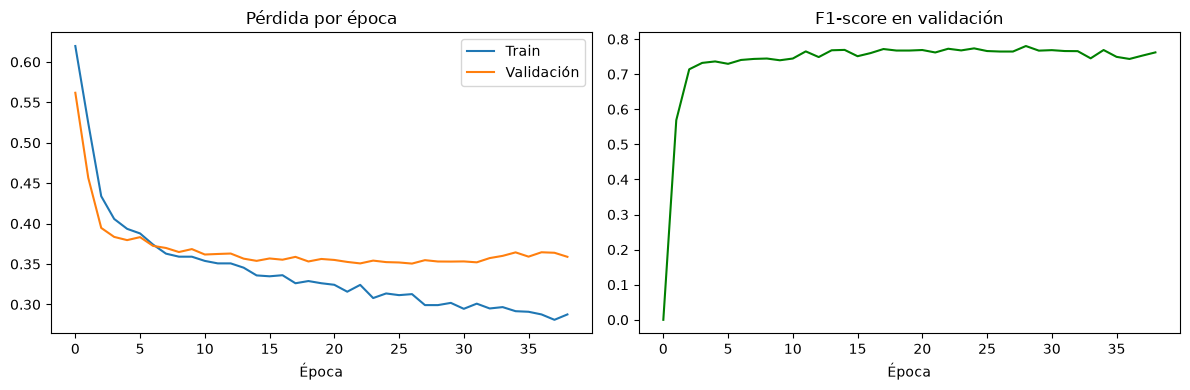

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_best["loss_train"], label="Train")
ax[0].plot(hist_best["loss_val"], label="Validación")
ax[0].set_title("Pérdida por época"); ax[0].set_xlabel("Época"); ax[0].legend()
ax[1].plot(hist_best["f1_val"], color="green")
ax[1].set_title("F1-score en validación"); ax[1].set_xlabel("Época")
plt.tight_layout(); plt.show()


## B5. Guardar el modelo entrenado
Se guarda solo `state_dict` (los pesos) junto con la arquitectura. Así la app de despliegue puede reconstruir la red sin necesitar este notebook.


In [24]:
torch.save({"state_dict": best_model.state_dict(),
            "config_arquitectura": {"input_dim": int(input_dim), **config_best}},
           "modelo_desercion.pt")
print("Guardado modelo_desercion.pt")


Guardado modelo_desercion.pt


# Evaluación final
## A12. Random Forest como comparación (no necesita el modelo de la Persona B)
Se muestra Accuracy y F1 en **train y en test**, como el profe en su notebook: si train es mucho mejor que test, hay sobreajuste.

In [25]:
rf = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(X_train_s, y_train)

print("=== RANDOM FOREST ===")
print("Accuracy TRAIN:", round(accuracy_score(y_train, rf.predict(X_train_s)), 4))
print("Accuracy TEST :", round(accuracy_score(y_test,  rf.predict(X_test_s)), 4))
print("F1-score TRAIN:", round(f1_score(y_train, rf.predict(X_train_s)), 4))
print("F1-score TEST :", round(f1_score(y_test,  rf.predict(X_test_s)), 4))

=== RANDOM FOREST ===
Accuracy TRAIN: 0.9968
Accuracy TEST : 0.861
F1-score TRAIN: 0.9951
F1-score TEST : 0.7593


## A13. Evaluar la red neuronal (cuando la Persona B entregue `best_model`)
Esta celda corre sola cuando `best_model` existe en el notebook. Si no, avisa y no falla.

=== RED NEURONAL (PyTorch) ===
Accuracy TRAIN: 0.9
Accuracy TEST : 0.8508
F1-score TRAIN: 0.8407
F1-score TEST : 0.7556

              precision    recall  f1-score   support

 No abandona       0.87      0.91      0.89       601
    Abandona       0.80      0.72      0.76       284

    accuracy                           0.85       885
   macro avg       0.83      0.82      0.82       885
weighted avg       0.85      0.85      0.85       885



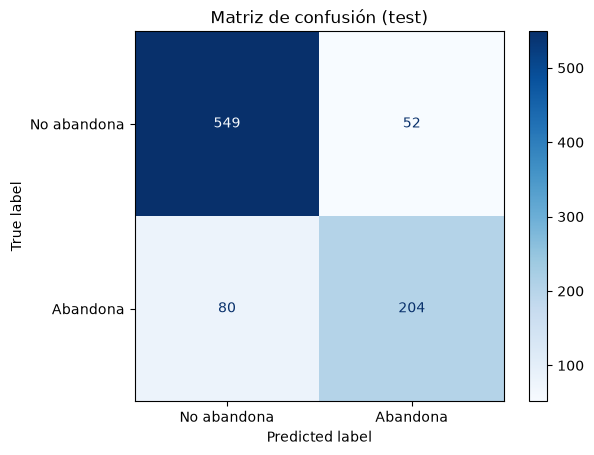

In [26]:
def probabilidades(model, loader):
    # Devuelve probabilidades de abandono y etiquetas reales de un DataLoader
    model.eval()                                # modo evaluación: apaga el Dropout
    probs, reales = [], []
    with torch.no_grad():                       # sin gradientes: más rápido
        for xb, yb in loader:
            probs.append(torch.sigmoid(model(xb.to(device))).cpu())   # sigmoide: logit -> probabilidad
            reales.append(yb)
    return torch.cat(probs).numpy().ravel(), torch.cat(reales).numpy().ravel()

if "best_model" in globals():
    p_tr, r_tr = probabilidades(best_model, train_loader)
    p_te, r_te = probabilidades(best_model, test_loader)
    pred_tr, pred_te = (p_tr >= 0.5).astype(int), (p_te >= 0.5).astype(int)   # umbral 0.5

    acc, f1 = accuracy_score(r_te, pred_te), f1_score(r_te, pred_te)
    print("=== RED NEURONAL (PyTorch) ===")
    print("Accuracy TRAIN:", round(accuracy_score(r_tr, pred_tr), 4))
    print("Accuracy TEST :", round(acc, 4))
    print("F1-score TRAIN:", round(f1_score(r_tr, pred_tr), 4))
    print("F1-score TEST :", round(f1, 4))
    print()
    print(classification_report(r_te, pred_te, target_names=["No abandona", "Abandona"]))

    # Matriz de confusión: filas = realidad, columnas = predicción
    ConfusionMatrixDisplay(confusion_matrix(r_te, pred_te),
                           display_labels=["No abandona", "Abandona"]).plot(cmap="Blues", values_format="d")
    plt.title("Matriz de confusión (test)")
    plt.show()
    # >>> Copiar Accuracy y F1 de TEST al resumen del artículo
else:
    print("Todavía no existe best_model. Esta evaluación se corre cuando la Persona B entregue el modelo entrenado.")

# Parte C: Despliegue
**Desplegar** un modelo es ponerlo en un lugar donde alguien lo pueda usar sin abrir este notebook. Aquí se hace en dos pasos: primero se prueba que el modelo guardado funciona de forma independiente, y luego se crea una aplicación web (`app.py`) con Streamlit.


## C1. Prueba del modelo guardado
Se reconstruye la red **desde cero** leyendo `modelo_desercion.pt`, `scaler.pkl` y `feature_info.pkl`, tal como lo hará la app. Si las probabilidades coinciden con las de `best_model`, el guardado es correcto.


In [27]:
def predecir_abandono(df_raw, modelo):
    # Recibe datos crudos de estudiantes y devuelve la probabilidad de abandono de cada uno
    entrada = torch.tensor(preparar_entrada(df_raw), dtype=torch.float32)
    modelo.eval()
    with torch.no_grad():
        return torch.sigmoid(modelo(entrada)).numpy().ravel()

# Reconstruir el modelo desde los archivos guardados (como en producción)
ckpt = torch.load("modelo_desercion.pt", map_location="cpu")
modelo_cargado = RedDesercion(**ckpt["config_arquitectura"])
modelo_cargado.load_state_dict(ckpt["state_dict"])

# Probar con 5 estudiantes reales del dataset
muestra = pd.read_csv("dataset.csv", encoding="utf-8-sig").sample(5, random_state=SEED)
probs_cargado = predecir_abandono(muestra, modelo_cargado.to("cpu"))
probs_original = predecir_abandono(muestra, best_model.to("cpu"))

resumen = pd.DataFrame({"Real": muestra["Target"].values,
                        "Prob. abandono": probs_cargado.round(3)})
display(resumen)
print("¿El modelo cargado da lo mismo que best_model?", np.allclose(probs_cargado, probs_original, atol=1e-6))
best_model.to(device);


,Real,Prob. abandono
0,Dropout,0.338
1,Graduate,0.014
2,Graduate,0.213
3,Graduate,0.126
4,Dropout,0.986


¿El modelo cargado da lo mismo que best_model? True


## C2. Aplicación web con Streamlit
La celda siguiente escribe el archivo `app.py`. La app: carga el modelo y los `.pkl` una sola vez, muestra un formulario con las 16 variables, las pasa por `preparar_entrada` (misma codificación y escalado del entrenamiento) y muestra la probabilidad de abandono con un nivel de riesgo.


In [28]:
%%writefile app.py
import joblib
import pandas as pd
import streamlit as st
import torch
import torch.nn as nn


class RedDesercion(nn.Module):
    # Misma arquitectura que en el entrenamiento (si cambia allá, debe cambiar aquí)
    def __init__(self, input_dim, h1=64, h2=32, dropout=0.3):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(input_dim, h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2),        nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h2, 1),
        )

    def forward(self, x):
        return self.red(x)


@st.cache_resource          # carga una sola vez, no en cada clic
def cargar_artefactos():
    info = joblib.load("feature_info.pkl")
    scaler = joblib.load("scaler.pkl")
    ckpt = torch.load("modelo_desercion.pt", map_location="cpu")
    modelo = RedDesercion(**ckpt["config_arquitectura"])
    modelo.load_state_dict(ckpt["state_dict"])
    modelo.eval()               # apaga el Dropout
    return info, scaler, modelo


def preparar_entrada(df_raw, info, scaler):
    # Idéntica a la del notebook: codifica y escala igual que en el entrenamiento
    d = df_raw[info["columnas_modelo"]].copy()
    if info["usar_onehot"]:
        for col in info["columnas_categoricas"]:
            d[col] = pd.Categorical(d[col], categories=info["niveles"][col])
        d = pd.get_dummies(d, columns=info["columnas_categoricas"], dtype=int)
    d = d.reindex(columns=info["columnas_finales"], fill_value=0)
    return scaler.transform(d.values)


ETIQUETAS = {
    "Mother's qualification": "Nivel de estudios de la madre (código)",
    "Father's qualification": "Nivel de estudios del padre (código)",
    "Mother's occupation": "Ocupación de la madre (código)",
    "Father's occupation": "Ocupación del padre (código)",
    "Debtor": "Tiene deudas con la institución",
    "Tuition fees up to date": "Matrícula al día",
    "Scholarship holder": "Tiene beca",
}
BINARIAS = ["Debtor", "Tuition fees up to date", "Scholarship holder"]


def etiqueta(col):
    if col in ETIQUETAS:
        return ETIQUETAS[col]
    sem = "1.er semestre" if "1st sem" in col else "2.º semestre"
    tipo = col[col.index("(") + 1:-1]
    nombres = {"credited": "unidades convalidadas", "enrolled": "unidades matriculadas",
               "evaluations": "evaluaciones presentadas", "approved": "unidades aprobadas",
               "grade": "promedio de notas (0 a 20)", "without evaluations": "unidades sin evaluaciones"}
    return f"{sem}: {nombres.get(tipo, tipo)}"


st.set_page_config(page_title="Riesgo de deserción", page_icon="🎓")
st.title("🎓 Predicción de deserción estudiantil")
st.caption("Red neuronal (PyTorch) entrenada con datos académicos y socioeconómicos. "
           "Es una herramienta de apoyo: no reemplaza la decisión de una persona.")

info, scaler, modelo = cargar_artefactos()
defecto = info["valores_defecto"]
datos = {}

with st.form("formulario"):
    st.subheader("Datos socioeconómicos")
    for col in info["columnas_modelo"]:
        if col in info["columnas_categoricas"]:
            opciones = info["niveles"][col]
            ini = opciones.index(int(defecto[col])) if int(defecto[col]) in opciones else 0
            datos[col] = st.selectbox(etiqueta(col), opciones, index=ini)
        elif col in BINARIAS:
            datos[col] = st.selectbox(etiqueta(col), [0, 1], index=int(defecto[col]),
                                      format_func=lambda v: "Sí" if v == 1 else "No")

    st.subheader("Datos académicos")
    for col in info["columnas_modelo"]:
        if col.startswith("Curricular"):
            if "(grade)" in col:
                datos[col] = st.number_input(etiqueta(col), 0.0, 20.0, float(defecto[col]), step=0.1)
            else:
                datos[col] = st.number_input(etiqueta(col), 0, 100, int(defecto[col]), step=1)

    enviar = st.form_submit_button("Calcular riesgo")

if enviar:
    entrada = preparar_entrada(pd.DataFrame([datos]), info, scaler)
    with torch.no_grad():
        prob = torch.sigmoid(modelo(torch.tensor(entrada, dtype=torch.float32))).item()

    st.subheader(f"Probabilidad de abandono: {prob * 100:.1f} %")
    st.progress(min(max(prob, 0.0), 1.0))
    if prob < 0.33:
        st.success("Riesgo BAJO")
    elif prob < 0.66:
        st.warning("Riesgo MEDIO: conviene hacer seguimiento.")
    else:
        st.error("Riesgo ALTO: se recomienda contactar al estudiante y ofrecer apoyo.")


Writing app.py


In [29]:
%%writefile requirements.txt
streamlit
torch
pandas
scikit-learn
joblib


Writing requirements.txt


## C3. Cómo ejecutar y publicar la app
**Local (en tu computador):**
1. Deja en una misma carpeta: `app.py`, `modelo_desercion.pt`, `scaler.pkl`, `feature_info.pkl` y `requirements.txt`.
2. Instala las librerías: `pip install -r requirements.txt`
3. Ejecuta: `streamlit run app.py` (se abre en `http://localhost:8501`).

**En línea (gratis, Streamlit Community Cloud):**
1. Sube esos 5 archivos a un repositorio de GitHub.
2. Entra a share.streamlit.io, conecta el repositorio y elige `app.py` como archivo principal.
3. Streamlit entrega un enlace público que se puede compartir.

> Importante: `scaler.pkl` y `feature_info.pkl` son parte del modelo. Si se entrena de nuevo, hay que volver a generarlos y subirlos juntos, porque el escalador y las columnas deben coincidir con los pesos de la red.
